# This Checks the heart data to predict heart disease 

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings

warnings.filterwarnings("ignore")
#sklearn and spicy.stats




In [3]:
df = pd.read_csv("heart.csv")

In [4]:
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


## EDA

In [5]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [6]:
df.shape

(918, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [8]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [9]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='HeartDisease'>

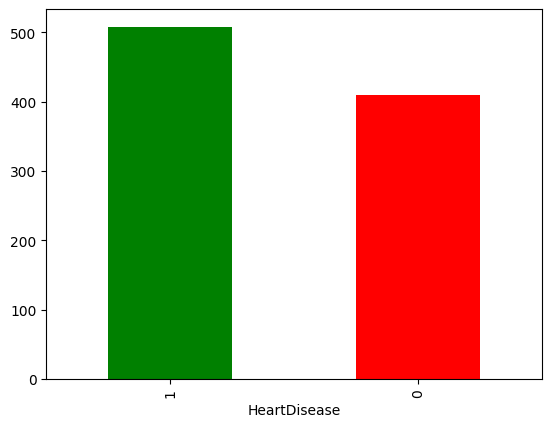

In [10]:
df['HeartDisease'].value_counts().plot(kind='bar', color=['green', 'red'])

In [11]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

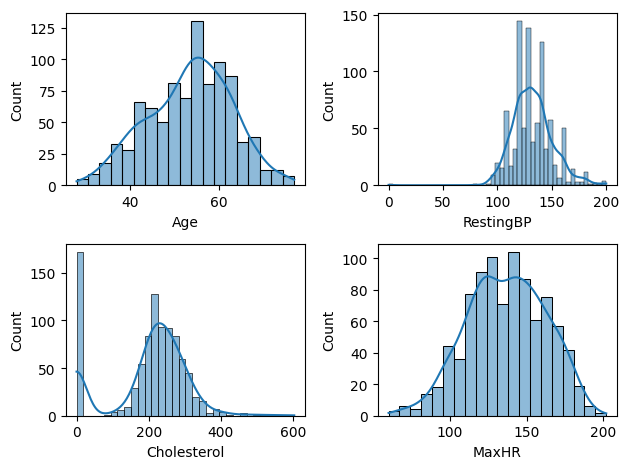

In [12]:
def ploting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde=True)

ploting('Age',1)
ploting('RestingBP',2)
ploting('Cholesterol',3)
ploting('MaxHR',4)

plt.tight_layout()# this prevents overlapping of subplots

In [13]:
df['RestingBP'].value_counts()

RestingBP
120    132
130    118
140    107
110     58
150     55
      ... 
101      1
117      1
192      1
129      1
164      1
Name: count, Length: 67, dtype: int64

In [14]:
df['RestingBP'].value_counts().loc[0]

np.int64(1)

In [15]:
(df['RestingBP']== 0).sum()

np.int64(1)

In [16]:
df['Cholesterol'].value_counts()

Cholesterol
0      172
254     11
220     10
223     10
204      9
      ... 
353      1
278      1
157      1
176      1
131      1
Name: count, Length: 222, dtype: int64

In [17]:
ch_mean =df.loc[df['Cholesterol']!=0 ,'Cholesterol'].mean()
df.loc[df['Cholesterol']== 0 ,'Cholesterol'] = ch_mean

In [18]:
(df['Cholesterol'] == 0).sum()

np.int64(0)

In [19]:
df['Cholesterol'].value_counts()

Cholesterol
244.635389    172
254.000000     11
220.000000     10
223.000000     10
204.000000      9
             ... 
353.000000      1
278.000000      1
157.000000      1
176.000000      1
131.000000      1
Name: count, Length: 222, dtype: int64

In [20]:
df['Cholesterol'] = df['Cholesterol'].round().astype(int)

In [21]:
df['Cholesterol'].value_counts()

Cholesterol
245    178
254     11
223     10
220     10
211      9
      ... 
353      1
278      1
157      1
176      1
131      1
Name: count, Length: 221, dtype: int64

In [22]:
mean_bp = df.loc[df['RestingBP'] != 0, 'RestingBP'].mean()

df.loc[df['RestingBP'] == 0, 'RestingBP'] = mean_bp

# OR  df['cholesterol']= df['cholesterol'].replace(0,mean)

In [23]:
(df['RestingBP'] == 0).sum() #verifyin if success

np.int64(0)

In [24]:
df['RestingBP'].value_counts()

RestingBP
120.0    132
130.0    118
140.0    107
110.0     58
150.0     55
        ... 
101.0      1
117.0      1
192.0      1
129.0      1
164.0      1
Name: count, Length: 67, dtype: int64

In [25]:
df['RestingBP'] = df['RestingBP'].round().astype(int)

In [26]:
df['RestingBP'].value_counts()


RestingBP
120    132
130    118
140    107
110     58
150     55
      ... 
101      1
117      1
192      1
129      1
164      1
Name: count, Length: 66, dtype: int64

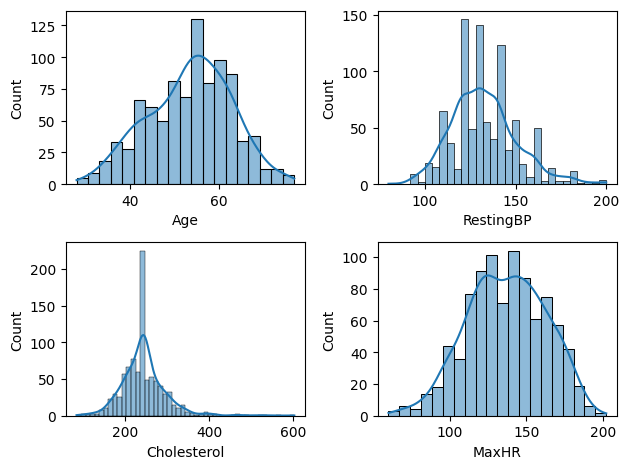

In [27]:
def ploting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde=True)

ploting('Age',1)
ploting('RestingBP',2)
ploting('Cholesterol',3)
ploting('MaxHR',4)

plt.tight_layout()# this prevents overlapping of subplots


<Axes: xlabel='Sex', ylabel='count'>

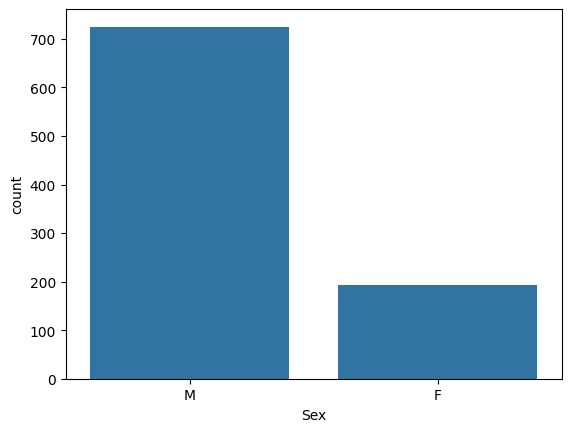

In [ ]:
sns.countplot(x= df['Sex']) #countplot is best for categorical variable 

<Axes: xlabel='ChestPainType', ylabel='count'>

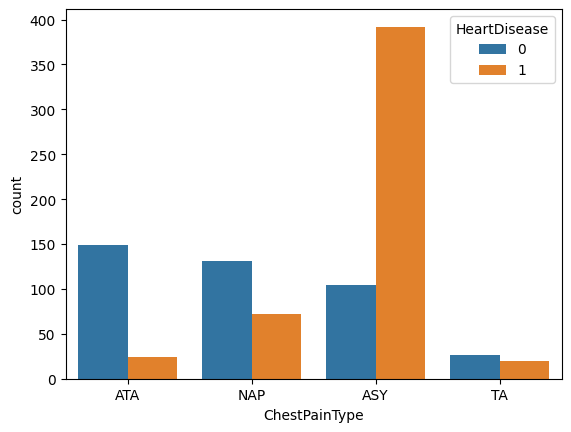

In [30]:
sns.countplot(x=df['ChestPainType'], hue =df['HeartDisease'])

<Axes: xlabel='Sex', ylabel='count'>

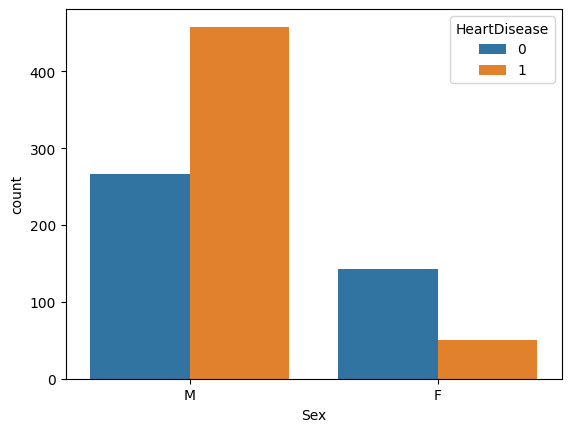

In [31]:
sns.countplot(x=df['Sex'],hue =df['HeartDisease'])

<Axes: xlabel='FastingBS', ylabel='count'>

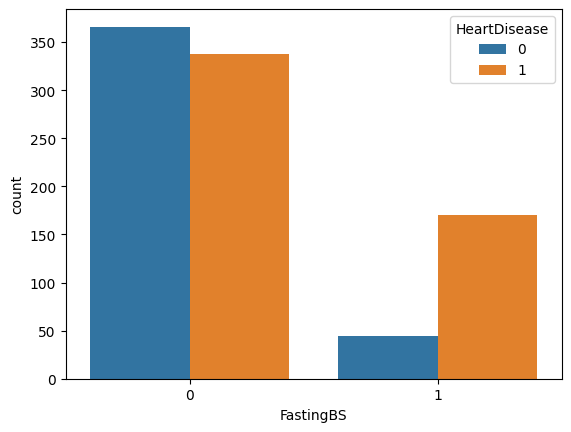

In [34]:
sns.countplot(x=df['FastingBS'],hue=df['HeartDisease'])

#### Boxplot can compare both numerical and categorical variable together

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

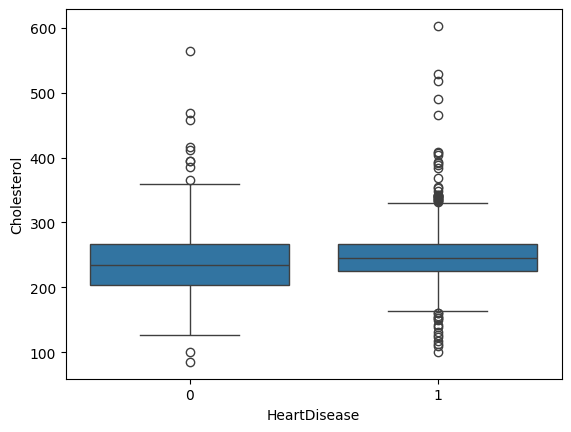

In [38]:
sns.boxplot(x='HeartDisease',y='Cholesterol' ,data =df)

#### violinplot :- similar to a box plot  Imagine you have 10 students and their heights:

150, 151, 152, 153, 154, 155, 170, 171, 172, 173

A normal boxplot tells you roughly where the middle is and where the extremes are.

A violin plot goes one step further: it shows the shape/distribution of the data.

🧠 Dummy analogy

Imagine 100 people are standing in a line according to their height.

If lots of people are standing around 150–160 cm, that area becomes fat.

If only a few people are around 180 cm, that area becomes thin.

<Axes: xlabel='HeartDisease', ylabel='Age'>

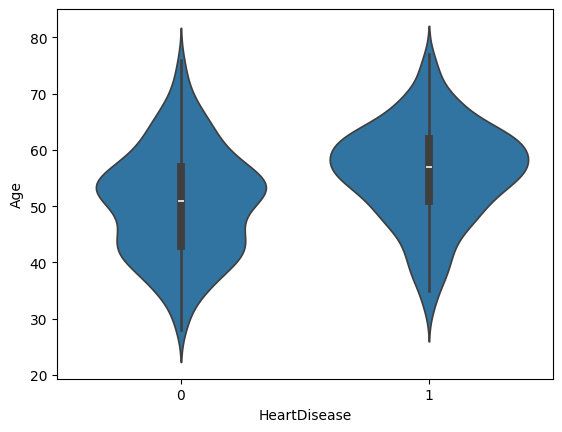

In [39]:
sns.violinplot(x='HeartDisease',y='Age' , data =df)

People with heart disease (1) tend to be older than those without heart disease (0).
The median age is approximately 51 years for 0 and 57 years for 1.
This suggests that age is associated with heart disease in this dataset.
As age increases, the distribution shifts toward people with heart disease (1).
People with heart disease have a higher median age (~57) compared with those without (~51).
Therefore, older age is associated with a higher likelihood of heart disease in this dataset.



<Axes: >

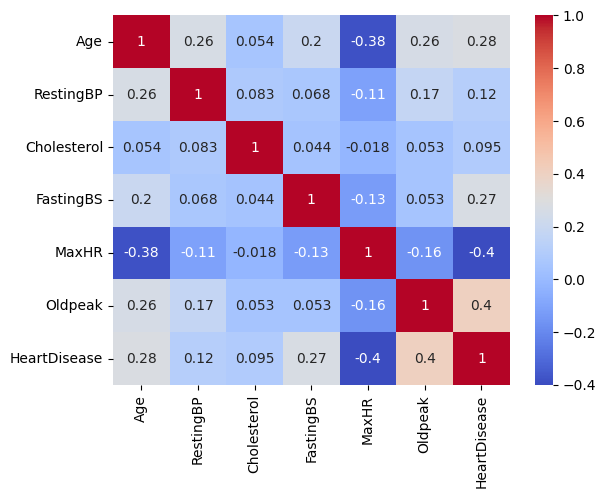

In [40]:
sns.heatmap(df.corr(numeric_only=True),annot=True ,cmap='coolwarm')

## Data Preprocessing and cleaning 

In [42]:
df_encode=pd.get_dummies(df)

In [43]:
df_encode

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_F,Sex_M,ChestPainType_ASY,...,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,False,True,False,...,False,False,False,True,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,True,False,False,...,True,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,False,True,False,...,False,False,False,False,True,True,False,False,False,True
3,48,138,214,0,108,1.5,1,True,False,True,...,False,False,False,True,False,False,True,False,True,False
4,54,150,195,0,122,0.0,0,False,True,False,...,True,False,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1.2,1,False,True,False,...,False,True,False,True,False,True,False,False,True,False
914,68,144,193,1,141,3.4,1,False,True,True,...,False,False,False,True,False,True,False,False,True,False
915,57,130,131,0,115,1.2,1,False,True,True,...,False,False,False,True,False,False,True,False,True,False
916,57,130,236,0,174,0.0,1,True,False,False,...,False,False,True,False,False,True,False,False,True,False


In [48]:
df_enc=pd.get_dummies(df ,drop_first=True)
df_enc.head()


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138,214,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150,195,0,122,0.0,0,True,False,True,False,True,False,False,False,True


In [45]:
df['ChestPainType'].value_counts()

ChestPainType
ASY    496
NAP    203
ATA    173
TA      46
Name: count, dtype: int64

In [ ]:
df_enc